The Sibils based dataset has a little problem, in that a lot of its entry have no candidate answer at all. This script simply clean the dataset to have one dataset that is full. 

In [16]:
import sys
sys.path.append('../')
import json
from pprint import pp

In [17]:
sibil_path = "data/PubMedQA/pubmedqa_rag_pool.json"

with open(sibil_path, "r", encoding="utf-8") as sibil_pool_json:
    sibil_pool = json.load(sibil_pool_json)

pp(sibil_pool[0])

{'id': '25429730',
 'query': 'Are group 2 innate lymphoid cells ( ILC2s ) increased in chronic '
          'rhinosinusitis with nasal polyps or eosinophilia?',
 'answer': 'As ILC2s are elevated in patients with CRSwNP, they may drive '
           'nasal polyp formation in CRS. ILC2s are also linked with high '
           'tissue and blood eosinophilia and have a potential role in the '
           'activation and survival of eosinophils during the Th2 immune '
           'response. The association of innate lymphoid cells in CRS provides '
           'insights into its pathogenesis.',
 'final_decision': 'yes',
 'pubmed_ids': [],
 'candidates': []}


For example, the one above has no candidate. 

Total entries:                10000
Entries with no candidate:    6752 (67.5%)
Entries with candidates:      3248 (32.5%)
Mean candidates (all):        24.3
Mean candidates (non-empty):  74.7
Median candidates (non-empty): 93
Max candidates (non-empty): 202
Min candidates (non-empty): 3


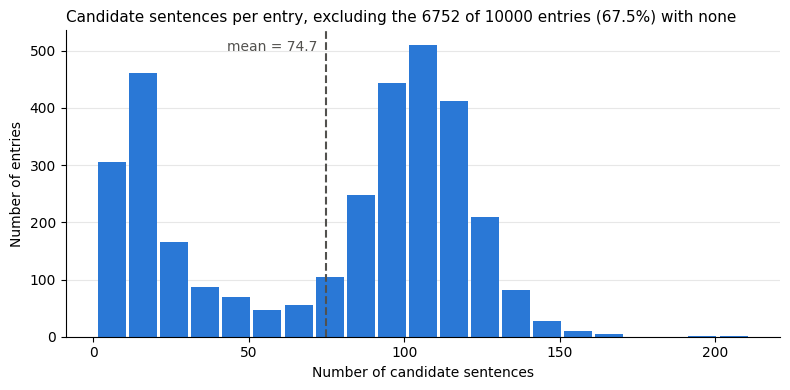

In [19]:
import matplotlib.pyplot as plt
import numpy as np

counts = np.array([len(entry["candidates"]) for entry in sibil_pool])
non_empty = counts[counts > 0]
n_empty = (counts == 0).sum()
pct_empty = n_empty / len(counts)

print(f"Total entries:                {len(counts)}")
print(f"Entries with no candidate:    {n_empty} ({pct_empty:.1%})")
print(f"Entries with candidates:      {len(non_empty)} ({1 - pct_empty:.1%})")
print(f"Mean candidates (all):        {counts.mean():.1f}")
print(f"Mean candidates (non-empty):  {non_empty.mean():.1f}")
print(f"Median candidates (non-empty): {np.median(non_empty):.0f}")
print(f"Max candidates (non-empty): {np.max(non_empty):.0f}")
print(f"Min candidates (non-empty): {np.min(non_empty):.0f}")

# Entries with no candidate are left out of the bars: they are so numerous that
# they would flatten the rest of the distribution, so the title reports them instead.
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(non_empty, bins=np.arange(1, non_empty.max() + 10, 10), color="#2a78d6", rwidth=0.9)
ax.axvline(non_empty.mean(), color="#52514e", linestyle="--", linewidth=1.5)
ax.annotate(f"mean = {non_empty.mean():.1f}", xy=(non_empty.mean(), 0.97), xycoords=("data", "axes fraction"),
            xytext=(-6, 0), textcoords="offset points", ha="right", va="top", color="#52514e")

ax.set_title(f"Candidate sentences per entry, excluding the {n_empty} of {len(counts)} entries ({pct_empty:.1%}) with none",
             fontsize=11, loc="left")
ax.set_xlabel("Number of candidate sentences")
ax.set_ylabel("Number of entries")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
sibil_pool_fixed = [entry for entry in sibil_pool if len(entry["candidates"]) > 0]
print(f"Kept {len(sibil_pool_fixed)} of {len(sibil_pool)} entries")

output_path = "data/PubMedQA/pubmedqa_rag_pool_fixed.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(sibil_pool_fixed, f, indent=2)